# First cosmological analysis: inferring ($\sigma_8, b_g$) from galaxy auto and galaxy x cmb lensing

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on.
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
    - The kappa map (`out_kappa_z000.fits`) can be found in `./data/test_box_x/results/`.
    - The QSO catalogs (`out_srcs_sx_xx.fits`) can be found in `./data/test_box_x/results)/`.
    - The galaxies auto-spectrum $C_{\ell}^{gg}$ and kappa $\times$ galaxies cross-spectrum $C_{\ell}^{\kappa g}$ can be found in `./data/test_box_x/cls/` with the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
- The notebook also fits for two parameters in the modelling accounting for CoLoRe finite cell size and a rescaling of the theory bias.

In [352]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import camb
import healpy as hp

from scipy.optimize import minimize, minimize_scalar
from scipy.interpolate import PchipInterpolator
from scipy.integrate import simpson
from scipy.constants import c
import zeus
from getdist import MCSamples, plots

import json
import re
import sys
sys.path.append('../')

from utils.rebinning import make_hybrid_bin_matrix

# functions

## theory

In [353]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [354]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # Initial CAMB params

    pars = camb.CAMBparams()
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )
    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax,
        nonlinear=nonlinear
    )

    # Final results
    results = camb.get_results(pars)

    return results

In [355]:
def W_g(z, kernel_context, kernel_args):
    '''
    Galaxy clustering kernel.
    '''

    # jacobian of transforming n(chi)=dN/dchi to n(z)=dN/dz, i.e. dchi/dz 
    c_kms = c * 1e-3
    Hz = kernel_context["Hz"]

    bz_interp = kernel_args["bz_interp"]
    nz_interp = kernel_args["nz_interp"]

    bias = bz_interp(z)
    bias = np.where(np.isnan(bias), 0, bias)  # set nan bias to zero
    ndensity = nz_interp(z)
    ndensity = np.where(np.isnan(ndensity), 0, ndensity)  # set nan density to zero

    return bias * ndensity * (Hz / c_kms)

In [356]:
def W_kappa(z, kernel_context):
    '''
    CMB lensing convergence kernel.
    '''

    # geometry
    a = 1.0 / (1.0 + z)

    # comoving distance to lens and source
    chi = kernel_context["chi"]
    chi_source = kernel_context["chi_source"]

    # cosmological parameters
    H0, om = kernel_context["cosmo_params"]
    c_kms = c * 1e-3

    # kernel prefactor
    W_prefactor = 1.5 * (H0 / c_kms)**2 * om * (chi_source - chi) / chi_source
    W_geom = chi / a

    return W_prefactor * W_geom

## data

In [357]:
def get_colore_cls(box_filename, cmb_lensing=False):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)

    if cmb_lensing:
        return data['ells'], data['cls'], data['err'], data['nside']
    else:
        return data['ells'], data['cls'], data['err'], data['nside'], data['shot_noise']

## fitting

In [358]:
def get_limber_cls_fit(
    theta,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    sigma8_fid,
    kp,
):
    '''
    Compute the angular gg and kg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8 = theta

    # parameter-dependent smoothing
    smooth_gg = np.exp(-k2_grid / kp**2)
    smooth_kg = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls_gg = simpson_weights @ (base_gg * smooth_gg)
    cls_kg = simpson_weights @ (base_kg * smooth_kg)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls_gg *= Abias**2 * growth_factor
    cls_kg *= Abias * growth_factor

    return cls_gg, cls_kg

In [359]:
def get_limber_cls_fit_gg(
    theta,
    k2_grid,
    simpson_weights,
    base,
    sigma8_fid,
    kp,
):
    '''
    Compute the angular gg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8 = theta

    # parameter-dependent smoothing
    smooth = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls = simpson_weights @ (base * smooth)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls *= Abias**2 * growth_factor

    return cls

In [360]:
def get_limber_cls_fit_kg(
    theta,
    k2_grid,
    simpson_weights,
    base,
    sigma8_fid,
    kp,
):
    '''
    Compute the angular kg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, sigma8 = theta

    # parameter-dependent smoothing
    smooth = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls = simpson_weights @ (base * smooth)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls *= Abias * growth_factor

    return cls

In [361]:
def get_limber_cls_fit_kk(
    theta,
    k2_grid,
    simpson_weights,
    base,
    sigma8_fid,
    kp,
):
    '''
    Compute the angular kk power spectra using the Limber approximation.
    '''

    # fitting parameters
    sigma8 = theta

    # parameter-dependent smoothing
    smooth = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls = simpson_weights @ (base * smooth)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls *= growth_factor

    return cls

In [362]:
def get_chi2(
    theta,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    B_gg,
    B_kg,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):
    '''
    Reduced chi-squared for joint gg and gk fitting.
    '''

    # compute theory
    cls_gg_theory, cls_kg_theory = get_limber_cls_fit(
        theta,
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        sigma8_fid,
        kp,
    )

    # rebin the theory to match the data
    cls_gg_theory = B_gg @ cls_gg_theory
    cls_kg_theory = B_kg @ cls_kg_theory

    # create theory vector
    cls_theory = np.concatenate((cls_gg_theory, cls_kg_theory))

    # residual
    residual = cls_data - cls_theory

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T
    
    return chi2

In [363]:
def get_chi2_single(
    theta,
    get_limber_cls_fit_single,
    k2_grid,
    simpson_weights,
    base,
    B,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):
    '''
    Reduced chi-squared for gg, kg and kk fitting.
    '''

    # compute theory
    cls_theory = get_limber_cls_fit_single(
        theta,
        k2_grid,
        simpson_weights,
        base,
        sigma8_fid,
        kp,
    )
    
    # rebin the theory to match the data
    cls_theory = B @ cls_theory

    # residual
    residual = cls_data - cls_theory

    #cls_theory_interp = PchipInterpolator(ells_kk, cls_theory * pixwin_kk**2)
    #residual = cls_data - cls_theory_interp(B_cmb @ ells_kk)

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T

    return chi2

## sampler

In [364]:
def log_prior(theta):
    '''
    Flat priors on A_bias and sigma8.
    '''

    Abias, sigma8 = theta

    if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5:
        return 0.0

    return -np.inf

In [365]:
def log_prior_gg(theta):
    '''
    Flat priors on A_bias and sigma8 for the single dataset of gg/kg.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    Abias, sigma8 = theta

    x = (Abias * sigma8)**2
    y = Abias * sigma8**2

    if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5:
        return 0.0

    return -np.inf

In [366]:
def log_prior_kg(theta):
    '''
    Flat priors on A_bias and sigma8 for the single dataset of gg/kg.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    Abias, sigma8 = theta

    if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5:
        return 0.0

    return -np.inf

In [367]:
def log_prior_single(theta):
    '''
    Flat priors on A_bias and sigma8 for the single dataset of gg/kg.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    if len(theta) == 2:
        Abias, sigma8 = theta

        if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5:
            return 0.0

        return -np.inf
    
    if len(theta) == 1:
        sigma8 = theta[0]

        if 0.5 < sigma8 < 1.5:
            return 0.0

        return -np.inf

In [368]:
def log_posterior(
    theta,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    B_gg,
    B_kg,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):
    '''
    Log-posterior for the joint gg and kg fitting.
    '''

    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2(
        theta,
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_gg,
        B_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    )

    return lp - 0.5 * chi2

In [369]:
def log_posterior_single(
    theta,
    get_limber_cls_fit_single,
    k2_grid,
    simpson_weights,
    base,
    B,
    cls_data,
    invcov_mat,
    sigma8_fid,
    kp,
):
    '''
    Log-posterior for the gg, kg and kk fitting.
    '''

    lp = log_prior_single(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2_single(
        theta,
        get_limber_cls_fit_single,
        k2_grid,
        simpson_weights,
        base,
        B,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    )

    return lp - 0.5 * chi2

## plotting

In [370]:
def format_catalog_name(cat_str):
    # Remove '_gal_' tags
    clean = re.sub(r'_gal_', ' ', cat_str, flags=re.IGNORECASE)
    # Format 'bin0' or 'bin_0' -> 'Bin 0'
    clean = re.sub(r'bin_?(\d+)', r'Bin \1', clean, flags=re.IGNORECASE)
    
    # Capitalize 'Bin' and set acronyms/surveys (LSST, DESI, QSO) to uppercase
    parts = clean.replace('_', ' ').split()
    formatted = [p.capitalize() if p.lower() == 'bin' else p.upper() for p in parts]
    return " ".join(formatted)

# Example usages:
# 'lsst_gal_bin0'  -> 'LSST Bin 0'
# 'desi_qso_bin0'  -> 'DESI QSO Bin 0'

In [371]:
def plot_cls_comparison(ells, cl_lin,
                        ells_sim_fit, cl_sim_fit, err_sim_fit, cl_lin_rebin_fit,
                        lmin_fit, lmax_fit, nbins_fit, chi2_best, reduced_chi2_best, sigma8, Abias, 
                        box_label, plot_title='', test_name='', xx=''):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 5), height_ratios=[2.5, 1], dpi=120, sharex=True, gridspec_kw={'hspace':0.05})

    for ax in (ax1, ax2):
        ax.tick_params(
            which='both',
            direction='in',
            top=True,
            right=True
        )

    # manual limber integration full redshift
    ax1.plot(ells, cl_lin, c='C0', ls='-', label=rf'Limber_linear')

    ax1.errorbar(ells_sim_fit, cl_sim_fit, yerr=err_sim_fit, fmt='k.', ms=5.0,
                 elinewidth=0.8, capsize=2.0, ecolor='k', label='CoLoRe '+box_label, zorder=10)
    
    ax1.errorbar(ells_sim_fit, cl_lin_rebin_fit, fmt='C1*', ms=7.0, mec='k', mew=0.0, label='Limber_linear-rebin', zorder=9)

    if Abias is not None:
        ax1.text(0.95, 0.95, rf'$\chi^2/ n_{{\text{{dof}}}} = {chi2_best:.0f}/{nbins_fit-2} = {reduced_chi2_best:.2f}$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
        ax1.text(0.95, 0.88, rf'$(A_{{bias}}= {Abias:.3f})$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
    else:
        ax1.text(0.95, 0.95, rf'$\chi^2/ n_{{\text{{dof}}}} = {chi2_best:.0f}/{nbins_fit-1} = {reduced_chi2_best:.2f}$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)
    ax1.text(0.95, 0.81, rf'$(\sigma_8= {sigma8:.3f})$', transform=ax1.transAxes, ha='right', va='top', fontsize=10)

    # shade most sensitive region to the analysis
    ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.1, label='Fitting region')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    #ax1.set_xlim(500, 1100)
    #ax1.set_ylim(1E-9, 9E-8)
    ax1.set_ylabel(rf'$C_{{L}}^{{{xx}}}$')
    ax1.legend(loc='lower left')

    ax1.grid(True, which='major', alpha=0.25)
    ax1.grid(True, which='minor', alpha=0.10)

    # plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
    pull = (cl_sim_fit - cl_lin_rebin_fit) / err_sim_fit
    pull_max = np.max(np.abs(pull))
    if xx == 'kk':
        print("Chi2/ndof = ", np.sum(pull**2) / (len(pull) - 1))
    else:
        print("Chi2/ndof = ", np.sum(pull**2) / (len(pull) - 2))

    # plot the relative error for low multipoles in the main panel
    ax2.errorbar(ells_sim_fit, pull, fmt='k.', ms=5.0, mec='k')
    ax2.axhspan(-1, 1, color='C0', alpha=0.12)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.12)
    ax2.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0)
    ax2.set_xscale('log')
    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(rf'$\Delta C_L^{{{xx}}}/\sigma$')
    ax2.set_ylim(-pull_max - 1, pull_max + 1)
    ax2.grid(True, which='major', alpha=0.25)
    ax2.grid(True, which='minor', alpha=0.10)

    fig.suptitle(plot_title, y=1.01)
    fig.savefig(f'../data/{box_label}/chains/cls_{xx}_{box_label}_{test_name}.png', bbox_inches='tight')
    #fig.savefig(f'../data/{box_label}/chain/cls_{xx}_{box_label}_{test_name}.pdf', bbox_inches='tight')
    plt.show()

# Fitting sample

## choosing data

In [372]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'ensemble_1' # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog = 'desi_qso'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
galaxy_catalog_bin = f'{galaxy_catalog}_bin0'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
params_path = f'../data/{box}/cosmo_params.json'

## measure and compare output n(z) with input n(z)

In [373]:
# load the galaxy bias distribution and create interpolator
z_bz, bz = np.loadtxt(f'../data/colore_files/bz/bz_{galaxy_catalog}.txt', unpack=True)
zbin_width_bz = np.diff(z_bz)[0]
bz_interp = PchipInterpolator(z_bz, bz, extrapolate=False)

# load the input n(z) histogram
z_nz_input, nz_input = np.loadtxt(f'../data/colore_files/nz/nz_{galaxy_catalog}.txt', unpack=True)
zbin_width_input = np.diff(z_nz_input)[0]

# load the output n(z) histogram output from colore
nz_file = np.load(f'../data/{box}/cls/nz_{galaxy_catalog}.npz')
z_nz_output, nz_output = nz_file['z_nz'], nz_file['nz']
zmean, zmin, zmax = nz_file['z_mean'], nz_file['z_min'], nz_file['z_max']
zbin_width_output = np.diff(z_nz_output)[0]

# load the bin output n(z) histogram output from colore
nz_file_bin = np.load(f'../data/{box}/cls/nz_{galaxy_catalog_bin}.npz')
z_nz_output_bin, nz_output_bin = nz_file_bin['z_nz'], nz_file_bin['nz']
zmean_bin, dz_bin, zmin_bin, zmax_bin = nz_file_bin['z_mean'], nz_file_bin['dz'], nz_file_bin['z_min'], nz_file_bin['z_max']
zbin_width_output_bin = np.diff(z_nz_output_bin)[0]
norm_output_bin = simpson(nz_output_bin, z_nz_output_bin)

In [374]:
# create n(z) interpolator for the input galaxy bias and redshift distribution
full_sky_area = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
nz_interp_input = PchipInterpolator(z_nz_input, nz_input * full_sky_area, extrapolate=False)

# create n(z) interpolator for the output redshift distributions
nz_interp_output = PchipInterpolator(z_nz_output, nz_output, extrapolate=False)
nz_interp_output_bin = PchipInterpolator(z_nz_output_bin, nz_output_bin/norm_output_bin, extrapolate=False)

In [375]:
# full redshift range for interpolation plot
zmin = 0.0
zmax = 3.8
z = np.linspace(zmin, zmax, 500)

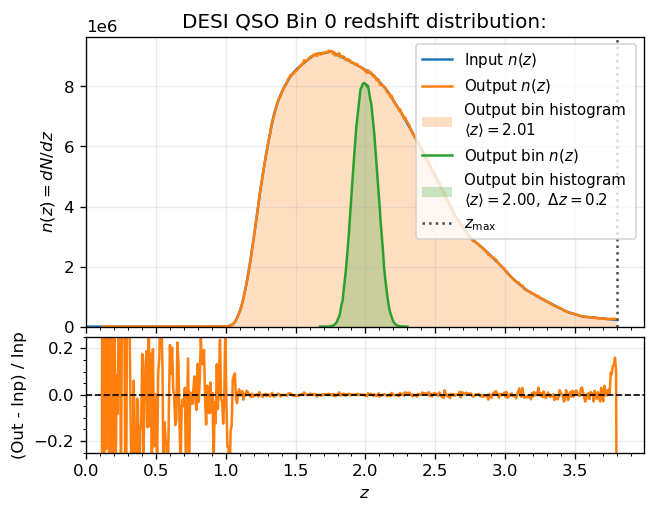

In [376]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4.5), dpi=120, sharex=True, gridspec_kw={'height_ratios':[3,1.2], 'hspace':0.05})

# Top panel
ax1.plot(z, nz_interp_input(z), 'C0-', lw=1.5, label=r'Input $n(z)$')  # plot the input n(z) distribution
ax1.plot(z, nz_interp_output(z), 'C1-', lw=1.5, label=r'Output $n(z)$')  # plot the output n(z) interpolated  distribution
ax1.bar(z_nz_output, nz_output, width=zbin_width_output, align='center', color='C1', alpha=0.25, 
        label='Output bin histogram \n'+rf'$\langle z \rangle = {zmean:.2f}$')  # plot the output n(z) histogram
ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')

if galaxy_catalog != galaxy_catalog_bin:  # change legend labels order depending on whether we are plotting the bin n(z) or not
    ax1.plot(z, nz_interp_output_bin(z)*norm_output_bin, 'C2-', lw=1.5, label=r'Output bin $n(z)$')  # plot the output n(z) interpolated  distribution for the bin
    ax1.bar(z_nz_output_bin, nz_output_bin, width=zbin_width_output_bin, align='center', color='C2', alpha=0.25, 
            label='Output bin histogram \n'+rf'$\langle z \rangle = {zmean_bin:.2f}, \ \Delta z = {dz_bin:.1f}$')  # plot the output n(z) histogram for the bin
    handles, labels = ax1.get_legend_handles_labels()
    order = [0, 1, 4, 3, 5, 2]
    ax1.legend([handles[i] for i in order], [labels[i] for i in order], frameon=True, loc='upper right', fontsize=9)
else:
    handles, labels = ax1.get_legend_handles_labels()
    order = [0, 1, 3, 2]
    ax1.legend([handles[i] for i in order], [labels[i] for i in order], frameon=True, loc='upper right', fontsize=9)

ax1.set_ylabel(r'$n(z) = dN/dz$')
ax1.set_title(f'{format_catalog_name(galaxy_catalog_bin)} redshift distribution:')
ax1.grid(alpha=0.25)

# Bottom panel
inp = nz_interp_input(z)
out = np.where(np.isnan(nz_interp_output(z)), 0, nz_interp_output(z))

ratio = np.full_like(inp, np.nan, dtype=float)
# threshold = 1e-1 * np.max(inp)  # threshold where the relative difference has appreciable weight
mask = np.abs(inp) > 0

ratio[mask] = (out[mask] - inp[mask]) / inp[mask]
ax2.plot(z, ratio, 'C1', lw=1.5)
ax2.axhline(0, color='k', ls='--', lw=1)
ax2.set_xlim(left=0)
ax2.set_ylim(-0.25, 0.25)
ax2.set_xlabel(r'$z$')
ax2.set_ylabel('(Out - Inp) / Inp')
ax2.minorticks_on()
ax2.grid(which='major', alpha=0.25)

if galaxy_catalog != galaxy_catalog_bin:
    plt.savefig(f'../data/{box}/plots/nz_{galaxy_catalog_bin}.png', dpi=300, bbox_inches='tight')
plt.show()

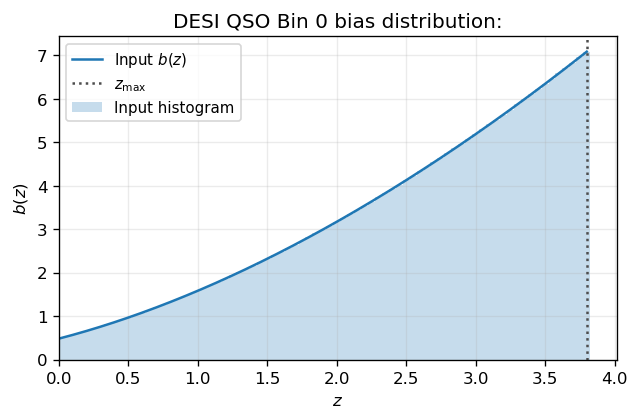

In [377]:
fig, (ax1) = plt.subplots(1, 1, figsize=(6, 3.5), dpi=120)

# Top panel
ax1.plot(z, bz_interp(z), 'C0-', lw=1.5, label=r'Input $b(z)$')  # plot the input b(z) distribution
ax1.bar(z_bz, bz, width=zbin_width_bz, align='center', color='C0', alpha=0.25, 
        label='Input histogram')  # plot the output n(z) histogram
ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')

ax1.legend(frameon=True, loc='upper left', fontsize=9)
ax1.set_ylabel(r'$b(z)$')
ax1.set_title(f'{format_catalog_name(galaxy_catalog_bin)} bias distribution:')
ax1.grid(alpha=0.25)
ax1.set_xlim(left=0)
ax1.set_xlabel(r'$z$')

if galaxy_catalog != galaxy_catalog_bin:
    plt.savefig(f'../data/{box}/plots/bz_{galaxy_catalog_bin}.png', dpi=300, bbox_inches='tight')
plt.show()

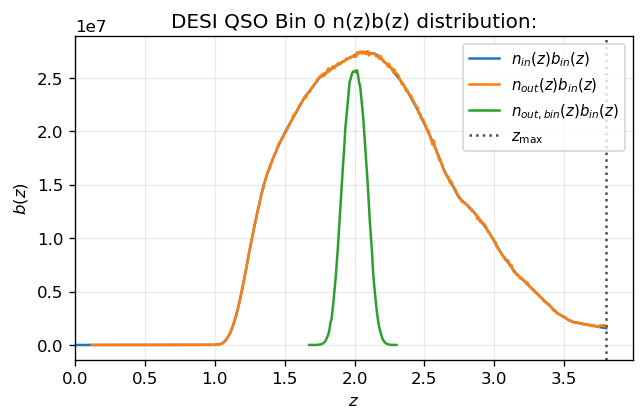

In [378]:
fig, (ax1) = plt.subplots(1, 1, figsize=(6, 3.5), dpi=120)

# Top panel
ax1.plot(z, bz_interp(z)*nz_interp_input(z), 'C0-', lw=1.5, label=r'$n_{in}(z)b_{in}(z)$')  # plot the input n(z) times input b(z) distribution
ax1.plot(z, bz_interp(z)*nz_interp_output(z), 'C1-', lw=1.5, label=r'$n_{out}(z)b_{in}(z)$')  # plot the output_bin n(z) times input b(z) distribution
ax1.plot(z, bz_interp(z)*nz_interp_output_bin(z)*norm_output_bin, 'C2-', lw=1.5, label=r'$n_{out, bin}(z)b_{in}(z)$')  # plot the output_bin n(z) times input b(z) distribution
ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')

ax1.legend(frameon=True, loc='upper right', fontsize=9)
ax1.set_ylabel(r'$b(z)$')
ax1.set_title(f'{format_catalog_name(galaxy_catalog_bin)} n(z)b(z) distribution:')
ax1.grid(alpha=0.25)
ax1.set_xlim(left=0)
ax1.set_xlabel(r'$z$')

plt.show()

In [379]:
# ------------------------------------------------------------
# Normalize input and output n(z)
# ------------------------------------------------------------

norm_input = simpson(nz_input, z_nz_input)
norm_output = simpson(nz_output, z_nz_output)

nz_input_norm = nz_input / norm_input
nz_output_norm = nz_output / norm_output


# ------------------------------------------------------------
# Interpolate onto a common redshift grid
# ------------------------------------------------------------

z_common = np.linspace(
    max(z_nz_input.min(), z_nz_output.min()),
    min(z_nz_input.max(), z_nz_output.max()),
    2000
)

nz_input_common = PchipInterpolator(
    z_nz_input,
    nz_input_norm,
    extrapolate=False
)(z_common)

nz_output_common = PchipInterpolator(
    z_nz_output,
    nz_output_norm,
    extrapolate=False
)(z_common)

# Outside the interpolation range, set to zero
nz_input_common = np.nan_to_num(nz_input_common, nan=0.0)
nz_output_common = np.nan_to_num(nz_output_common, nan=0.0)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

# Mean redshift
zmean_input = simpson(z_common * nz_input_common, z_common)
zmean_output = simpson(z_common * nz_output_common, z_common)

delta_zmean = zmean_output - zmean_input


# Total variation / L1 distance
l1_distance = 0.5 * simpson(
    np.abs(nz_output_common - nz_input_common),
    z_common
)


# RMS difference
rms_difference = np.sqrt(
    simpson(
        (nz_output_common - nz_input_common)**2,
        z_common
    )
)


# Maximum relative difference in the relevant part of n(z)
threshold = 1e-3 * np.max(nz_input_common)

mask = nz_input_common > threshold

relative_difference = np.full_like(
    nz_input_common,
    np.nan
)

relative_difference[mask] = (
    nz_output_common[mask] - nz_input_common[mask]
) / nz_input_common[mask]

max_relative_difference = np.max(
    np.abs(relative_difference[mask])
)


# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print(f"Input  <z> = {zmean_input:.6f}")
print(f"Output <z> = {zmean_output:.6f}")
print(f"Delta <z>  = {delta_zmean:+.6e}")
print()
print(f"Total variation distance = {l1_distance:.6e} "
      f"({100*l1_distance:.3f}%)")
print(f"RMS difference                = {rms_difference:.6e}")
print(
    f"Max relative difference "
    f"(n > 1e-3 n_max)             = {max_relative_difference:.3%}"
)

Input  <z> = 2.004799
Output <z> = 2.014177
Delta <z>  = +9.377964e-03

Total variation distance = 2.908372e-03 (0.291%)
RMS difference                = 4.787423e-03
Max relative difference (n > 1e-3 n_max)             = 37.691%


# First analysis: $\sigma_8$ and $b_g$ fit

The plan is to infer $\sigma_8$ by breaking the degeneracy with galaxy bias $b(z)$ by combining galaxy auto and galaxy x cmb lensing spectrums. However, we are working with $A_{\rm bias}$ instead of the bias directly, for validation purpouses, so we will be fitting for this parameter instead of the effective bias over the redshift bin $b_{\rm eff}$.

## camb init

In [380]:
# get cosmological parameters
cosmo_dict = load_cosmology(params_path)
h_fid = cosmo_dict['h']
z_max = cosmo_dict["z_max"]
z_star = cosmo_dict["z_out"]
sigma8_fid = cosmo_dict['sigma_8']
# cosmological parameters needed by kernels
H0 = h_fid * 100
om = cosmo_dict["omega_M"]

In [381]:
# set the redshift range for the boltzmann solver
z_min = 0.0
nz = 250
z_pk = zmin + np.exp(np.log(z_max - z_min + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1] # reverse to have higher redshift first for better interpolation at high z

# [1/Mpc] set the maximum k for CAMB results
kmax = 1.0 

# get CAMB results
results_lin = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=kmax,
    nonlinear=False
)

## data and covariance

### fitting range

In [382]:
R_smoothing = 2 # [Mpc/h] smoothing scale, default value from CoLoRe
kp = 1 / (R_smoothing/h_fid)  # [1/Mpc]
print(f"Default smoothing scale: kp = {kp:.3f} 1/Mpc")

Default smoothing scale: kp = 0.337 1/Mpc


In [383]:
# Multipole range for joint, gg and kg binning
r_min = 40  # [Mpc/h] minimum scale for binning
k_max = (2*np.pi) / r_min  # [h/Mpc] maximum scale for binning
chi_h = results_lin.comoving_radial_distance(float(zmean_bin)) * h_fid # [Mpc/h] comoving distance to the mean redshift of the bin in Mpc
lmax_fit = int(k_max * chi_h - 0.5)
lmin_fit = 20  # minimum multipole for fitting, avoiding low multipoles where Limber and cosmic variance effects are significant
nbins_fit = 30 # number of multipole bins for binning

# Multipole range for kk fitting
lmax_fit_kk = 300  # maximum multipole for kk fitting
lmin_fit_kk = 20  # minimum multipole for fitting, avoiding low multipoles where Limber and cosmic variance effects are significant
nbins_fit_kk = 30  # number of multipole bins for binning

print(f"Minimum scale: r_min = {r_min:.2f} Mpc/h ")
print(f"\t       k_max = {k_max:.3f} h/Mpc")

print(f"Minimum multipole: lmin_fit = {lmin_fit}")
print(f"Maximum multipole: lmax_fit = {lmax_fit}")
print(f"Nº multipole bins: nbins_fit = {nbins_fit} \n")

print(f"Minimum kk multipole: lmin_fit = {lmin_fit_kk}")
print(f"Maximum kk multipole: lmax_fit = {lmax_fit_kk}")
print(f"Nº kk multipole bins: nbins_fit = {nbins_fit_kk}")

Minimum scale: r_min = 40.00 Mpc/h 
	       k_max = 0.157 h/Mpc
Minimum multipole: lmin_fit = 20
Maximum multipole: lmax_fit = 561
Nº multipole bins: nbins_fit = 30 

Minimum kk multipole: lmin_fit = 20
Maximum kk multipole: lmax_fit = 300
Nº kk multipole bins: nbins_fit = 30


### get data and covariance

In [384]:
# load and rebin gg data
box_path_gg = f'../data/{box}/cls/cl_gg_{galaxy_catalog_bin}.npz'
ells_gg_data, cls_gg_data, err_gg_data, nside_gg, shot_noise = get_colore_cls(box_path_gg)

# load and rebin kg data
box_path_kg = f'../data/{box}/cls/cl_kg_{galaxy_catalog_bin}.npz'
ells_kg_data, cls_kg_data, err_kg_data, nside_kg, shot_noise = get_colore_cls(box_path_kg)

# load and rebin kk data
box_path_kk = f'../data/{box}/cls/cl_kk.npz'
ells_kk_data, cls_kk_data, err_kk_data, nside_kk = get_colore_cls(box_path_kk, cmb_lensing=True)

# smooth with healpix pixel window function
pixwin_gg = hp.pixwin(nside_gg, lmax=lmax_fit)[lmin_fit:]
pixwin_kg = hp.pixwin(nside_kg, lmax=lmax_fit)[lmin_fit:]
pixwin_kk = hp.pixwin(nside_kk, lmax=lmax_fit_kk)[lmin_fit_kk:]

# rebin the theory to match the data
Bcov_gg = make_hybrid_bin_matrix(
    ells_gg_data,
    nbins=nbins_fit,
    ell_min=lmin_fit,
    ell_max=lmax_fit,
)

# rebin the theory to match the data
Bcov_kg = make_hybrid_bin_matrix(
    ells_kg_data,
    nbins=nbins_fit,
    ell_min=lmin_fit,
    ell_max=lmax_fit,
)

# rebin the theory to match the data
Bcov_kk = make_hybrid_bin_matrix(
    ells_kk_data,
    nbins=nbins_fit_kk,
    ell_min=lmin_fit_kk,
    ell_max=lmax_fit_kk,
)

In [385]:
# rebin the data to the fitting range
cls_gg_data_rebin = Bcov_gg @ cls_gg_data
cls_kg_data_rebin = Bcov_kg @ cls_kg_data
cls_kk_data_rebin = Bcov_kk @ cls_kk_data

# create data vector for joint fitting
cls_data = np.concatenate((cls_gg_data_rebin, cls_kg_data_rebin))

In [386]:
# compute and rebin covariance
fsky = 1
nl_gg = np.ones_like(ells_kg_data) * shot_noise
cross_cov = (2 / ((2*ells_kg_data + 1)*fsky)) * ((cls_gg_data[:len(ells_kg_data)] + nl_gg) * cls_kg_data)
var_gg = err_gg_data**2
var_kg = err_kg_data**2
var_kk = err_kk_data**2

# rebin the covariance matrix to fitting range
cov_mat_gg_rebin = Bcov_gg @ np.diag(var_gg) @ Bcov_gg.T
cov_mat_kg_rebin = Bcov_kg @ np.diag(var_kg) @ Bcov_kg.T
cov_mat_kk_rebin = Bcov_kk @ np.diag(var_kk) @ Bcov_kk.T
cross_cov_rebin = Bcov_gg @ np.diag(cross_cov) @ Bcov_kg.T
rho_pearson_rebin = cross_cov_rebin / np.sqrt(np.diag(cov_mat_gg_rebin) * np.diag(cov_mat_kg_rebin))

# create the rebinned full covariance matrix
cov_mat = np.block([[cov_mat_gg_rebin, cross_cov_rebin],
                    [cross_cov_rebin.T, cov_mat_kg_rebin]])

# invert the covariance matrix
invcov_mat = np.linalg.inv(cov_mat)
invcov_mat_gg = np.linalg.inv(cov_mat_gg_rebin)
invcov_mat_kg = np.linalg.inv(cov_mat_kg_rebin)
invcov_mat_kk = np.linalg.inv(cov_mat_kk_rebin)

## theory

In [387]:
# get matter power spectrum interpolator
pk_interp_lin = results_lin.get_matter_power_interpolator(
    nonlinear=False,
    hubble_units=False,
    k_hunit=False,
    var1='delta_tot',
    var2='delta_tot'
)
chi_star = results_lin.comoving_radial_distance(z_star)

# shared kernel context
kernel_context = {
    "chi_source": chi_star,
    "cosmo_params": (H0, om),
}

# precompute the z, chi(z) and H(z) grids for Limber integrand
z_grid = np.linspace(1e-4, z_max, nz)
chi_grid = results_lin.comoving_radial_distance(z_grid)
Hz_grid = results_lin.hubble_parameter(z_grid)

# add to kernel context for use in kernels and Limber integrand
kernel_context["chi"] = chi_grid
kernel_context["Hz"] = Hz_grid

# defined the kernel arguments 
kernel_args={
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output_bin}

# precompute the kernel grids for Limber integrand
Wk_grid = W_kappa(z_grid, kernel_context)
Wg_grid = W_g(z_grid, kernel_context, kernel_args)

In [388]:
# multipoles and cls
ells = np.arange(lmin_fit, lmax_fit + 1)
ells_kk = np.arange(lmin_fit_kk, lmax_fit_kk + 1)

# geometry
chi = chi_grid[:, None]        # (Nz,1)
Hz = Hz_grid[:, None]          # (Nz,1)
c_kms = c * 1e-3

# Limber k-grid (Nz, Nell)
k_grid = (ells[None, :] + 0.5) / chi
k_grid_kk = (ells_kk[None, :] + 0.5) / chi
k2_grid = k_grid**2
k2_grid_kk = k_grid_kk**2

# valid CAMB region
mask = (k_grid > 0) & (k_grid < kmax)
mask_kk = (k_grid_kk > 0) & (k_grid_kk < kmax)

# evaluate P(k,z) for all z and ell
pk_lin = np.zeros_like(k_grid)
pk_lin[mask] = pk_interp_lin.P(
    np.broadcast_to(z_grid[:, None], k_grid.shape)[mask],
    k_grid[mask],
    grid=False,
)
pk_lin_kk = np.zeros_like(k_grid_kk)
pk_lin_kk[mask_kk] = pk_interp_lin.P(
    np.broadcast_to(z_grid[:, None], k_grid_kk.shape)[mask_kk],
    k_grid_kk[mask_kk],
    grid=False,
)

# integrand without smoothing
base_gg = pk_lin * (c_kms / Hz) * (Wg_grid[:, None] * Wg_grid[:, None]) / chi**2
base_kg = pk_lin * (c_kms / Hz) * (Wk_grid[:, None] * Wg_grid[:, None]) / chi**2
base_kk = pk_lin_kk * (c_kms / Hz) * (Wk_grid[:, None] * Wk_grid[:, None]) / chi**2

# rebin the theory to match the data
B = make_hybrid_bin_matrix(
    ells,
    nbins=nbins_fit,
    ell_min=lmin_fit,
    ell_max=lmax_fit,
)

B_kk = make_hybrid_bin_matrix(
    ells_kk,
    nbins=nbins_fit_kk,
    ell_min=lmin_fit_kk,
    ell_max=lmax_fit_kk,
)

# apply pixel window functions
B_smooth_gg = B * (pixwin_gg[None, :])**2
B_smooth_kg = B * (pixwin_kg[None, :])**2  
B_smooth_kk = B_kk * (pixwin_kk[None, :])**2

In [389]:
# Exact weights corresponding to scipy.integrate.simpson(..., x=z_grid)
simpson_weights = np.zeros(len(z_grid))

for i in range(len(z_grid)):
    basis = np.zeros(len(z_grid))
    basis[i] = 1.0
    simpson_weights[i] = simpson(basis, x=z_grid)

In [390]:
sigma8_camb = results_lin.get_sigma8_0()

print(f"sigma8 from CoLoRe config = {sigma8_fid:.7f}")
print(f"sigma8 from CAMB          = {sigma8_camb:.7f}")
print(f"Difference                = {sigma8_camb - sigma8_fid:+.7f}")
print(f"Relative difference       = "
      f"{(sigma8_camb / sigma8_fid - 1) * 100:+.4f}%")

sigma8 from CoLoRe config = 0.8135066
sigma8 from CAMB          = 0.8134498
Difference                = -0.0000568
Relative difference       = -0.0070%


In [391]:
print(f"CAMB kmax requested: {kmax:.3f} 1/Mpc")

for name, kg in [
    ("gg/kg", k_grid),
    ("kk", k_grid_kk),
]:
    print(f"\n{name}:")
    print(f"  k min = {np.min(kg):.4g} 1/Mpc")
    print(f"  k max = {np.max(kg):.4g} 1/Mpc")
    print(f"  fraction above kmax = {np.mean(kg > kmax):.3%}")

CAMB kmax requested: 1.000 1/Mpc

gg/kg:
  k min = 0.002852 1/Mpc
  k max = 1261 1/Mpc
  fraction above kmax = 1.948%

kk:
  k min = 0.002852 1/Mpc
  k max = 674.7 1/Mpc
  fraction above kmax = 1.156%


## likelihood evaluation timer

In [392]:
x0 = [1.0, sigma8_fid]  # initial guess for Abias and sigma8
niter = 1000 # number of iterations for timing the posterior evaluation
start_x0 = x0 + 1e-1 * np.random.randn(niter, len(x0))  # generate random starting points for each iteration
t = []

import time

for i in range(niter):
    t0 = time.perf_counter()
    value = log_posterior(
            start_x0[i],
            k2_grid,
            simpson_weights,
            base_gg,
            base_kg,
            B_smooth_gg,
            B_smooth_kg,
            cls_data,
            invcov_mat,
            sigma8_fid,
            kp
        )
    t.append(time.perf_counter() - t0)

print(f"posterior evaluation: {np.mean(t):.5f} s")

posterior evaluation: 0.00096 s


In [393]:
test = [1.0, sigma8_fid]  # test point for posterior evaluation
log_posterior(
            test,
            k2_grid,
            simpson_weights,
            base_gg,
            base_kg,
            B_smooth_gg,
            B_smooth_kg,
            cls_data,
            invcov_mat,
            sigma8_fid,
            kp,
        )

np.float64(-50.708546019584745)

In [394]:
test = [1.0, sigma8_fid]  # test point for posterior evaluation
log_posterior_single(
            test,
            get_limber_cls_fit_kg,
            k2_grid,
            simpson_weights,
            base_kg,
            B_smooth_kg,
            cls_kg_data_rebin,
            invcov_mat_kg,
            sigma8_fid,
            kp,
        )

np.float64(-23.070306556768564)

## Joint dataset

### minimizer & sampler

In [395]:
# perform the chi2 minimization
x0 = [1.0, sigma8_fid]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5)]  # bounds for Abias and sigma8
result = minimize(
    get_chi2,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_smooth_gg,
        B_smooth_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_sigma8  = result.x
chi2_best = result.fun
reduced_chi2_best = result.fun/(nbins_fit-len(result.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.3f}")
print(f"Best-fit A_bias: {best_Abias:.3f}")
print(f"Chi2/ndof: {chi2_best:.2f}/({nbins_fit}-{len(result.x)}) = {reduced_chi2_best:.3f}")

Best-fit sigma8: 0.749
Best-fit A_bias: 1.079
Chi2/ndof: 72.64/(30-2) = 2.594


In [396]:
# perform the chi2 minimization for kk data
bounds = [0.5, 1.5]  # bounds for sigma8
result_kk = minimize_scalar(
    get_chi2_single,
    bounds=bounds,
    method='bounded',
    args=(
        get_limber_cls_fit_kk,
        k2_grid_kk,
        simpson_weights,
        base_kk,
        B_smooth_kk,
        cls_kk_data_rebin,
        invcov_mat_kk,
        sigma8_fid,
        kp,
        )
)

# extract best-fit parameters, covariance and chi2
best_sigma8_kk  = result_kk.x
chi2_best_kk = result_kk.fun
reduced_chi2_best_kk = result_kk.fun/(nbins_fit_kk-1)  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8_kk:.3f}")
print(f"Chi2/ndof: {chi2_best_kk:.2f}/{nbins_fit_kk-1} = {reduced_chi2_best_kk:.3f}")

Best-fit sigma8: 0.809
Chi2/ndof: 22.91/29 = 0.790


In [ ]:
chi2_fid_kk = get_chi2_single(
    sigma8_fid,
    get_limber_cls_fit_kk,
    k2_grid_kk,
    simpson_weights,
    base_kk,
    B_smooth_kk,
    cls_kk_data_rebin,
    invcov_mat_kk,
    sigma8_fid,
    kp,
)

print(f"chi2 at fiducial sigma8 = {chi2_fid_kk:.3f}")
print(f"chi2 at best fit         = {chi2_best_kk:.3f}")
print(f"Delta chi2               = {chi2_fid_kk - chi2_best_kk:.3f}")

In [ ]:
# Theory at the fiducial sigma8
cl_kk_fid = get_limber_cls_fit_kk(
    sigma8_fid,
    k2_grid_kk,
    simpson_weights,
    base_kk,
    sigma8_fid,
    kp,
)

cl_kk_fid_binned = B_smooth_kk @ cl_kk_fid

# Fractional residual per bandpower
fractional_residual = (
    cls_kk_data_rebin - cl_kk_fid_binned
) / cl_kk_fid_binned

# Significance per bandpower using the current covariance
sigma_band = np.sqrt(np.diag(cov_mat_kk_rebin))
residual_sigma = (
    cls_kk_data_rebin - cl_kk_fid_binned
) / sigma_band

print("Bin  ell         fractional residual   residual / sigma")
for i, (frac, sig) in enumerate(
    zip(fractional_residual, residual_sigma)
):
    print(f"{i:2d}   {(B_kk @ ells_kk)[i]:3f}   {frac:+.5f}             {sig:+.3f}")

In [ ]:
np.mean(residual_sigma)

In [ ]:
# scipy best fit as starting point for MCMC
theta0 = result.x

# initialize the MCMC
ndim = len(theta0)
nwalkers = 16  # number of walkers for MCMC, normally 3 times the number of dimensions

# small Gaussian scatter around the best-fit point
scatter = theta0 * [0.05, 0.05]  # scatter for Abias and sigma8

# initialize walkers around best fit
start = theta0 + scatter * np.random.randn(nwalkers, ndim)

In [ ]:
# initialize the sampler
sampler = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior,
    args=(
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_smooth_gg,
        B_smooth_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
        kp,
    ),
)

# run the MCMC
nsteps = 20000
sampler.run_mcmc(start, nsteps, progress=True)
sampler.summary

In [ ]:
# save the chains to a file
raw_chain = sampler.get_chain()

map_idx = np.argmax(sampler.get_log_prob(flat=True))
map_estimate = sampler.get_chain(flat=True)[map_idx]

truths = np.array([1.0, sigma8_fid])
np.savez(f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}_rmin{r_min}.npz", 
         chain=raw_chain, 
         nsteps=nsteps, nwalkers=nwalkers, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit, 
         map_estimate=map_estimate, bestfit_values=result.x, true_values=truths)

### visualization

In [ ]:
# load the chains from the file to visualize the results and clean the samples
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal_bin0'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps = 20000  # number of steps for MCMC
r_min = 40  # minimum scale for fitting in Mpc/h

chain_filename = f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}_rmin{r_min}.npz"
chain_file = np.load(chain_filename, allow_pickle=True)

chain = chain_file['chain']
nsteps = chain_file['nsteps']
nwalkers = chain_file['nwalkers']
ndim = chain_file['ndim']
map_estimate = chain_file['map_estimate']
bestfit_values = chain_file['bestfit_values']
truths = chain_file['true_values']

In [ ]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)
axis_labels = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
]

for i in range(ndim):
    for walker in range(chain.shape[1]):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain[:, walker, i], alpha=0.5)
    ax.set_xlim(0, len(chain))
    ax.set_ylabel(axis_labels[i])
axes[-1].set_xlabel('steps')
plt.show()

In [ ]:
chain[200, :, -1]

In [ ]:
# declare the burnin and deleted walkers for each chain
burnin = 500
deleted_walkers = np.array([]).astype(int)  # indices of walkers to delete

# clean the chains from deleted walkers, discard burnin and reshape to 2D arrays for corner plots
clean_chain = np.delete(chain, obj=deleted_walkers, axis=1)
clean_chain = clean_chain[burnin:, : , :]  # discard the first burnin steps
clean_samples = clean_chain.reshape(-1, clean_chain.shape[-1])  # reshape to 2D array for corner plot

# save the cleaned chains to a file
np.savez(chain_filename, 
         chain=chain, clean_samples=clean_samples, 
         nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit, 
         map_estimate=map_estimate, bestfit_values=bestfit_values, true_values=truths)

In [ ]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)

for i in range(ndim):
    for walker in range(nwalkers-len(deleted_walkers)):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(clean_chain[:, walker, i], alpha=0.5)
    ax.set_xlim(0, clean_chain.shape[0])
    ax.set_ylabel(axis_labels[i])
axes[-1].set_xlabel('steps')
plt.show()

### plotter

In [ ]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal_bin0'  # options: 'desi_bgs_binx', 'desi_elg_binx', 'desi_lrg_binx', 'desi_qso_binx', 'lsst_gal_binx'

nsteps = 20000  # number of steps for MCMC
nsteps_single = 20000  # number of steps for MCMC
nsteps_kk = 2000 # number of steps for MCMC

r_min = 40  # minimum scale for fitting in Mpc/h
lmax_fit_kk = 1000  # maximum multipole for kk fitting

In [ ]:
# load the chains from the file 
chain_file = np.load(f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}_rmin{r_min}.npz", allow_pickle=True)
chain_file_gg = np.load(f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_rmin{r_min}.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_rmin{r_min}.npz", allow_pickle=True)
chain_file_kk = np.load(f"../data/{box}/chains_new/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz", allow_pickle=True)

# extract the chain and samples
chain = chain_file['chain']
samples = chain_file['clean_samples']
samples_gg = chain_file_gg['clean_samples'] 
samples_kg = chain_file_kg['clean_samples']
samples_kk = chain_file_kk['clean_samples']

# extract the chain parameters
nsteps = chain_file['nsteps']
nwalkers = chain_file['nwalkers']
ndim = chain_file['ndim']
deleted_walkers = chain_file['deleted_walkers']
burnin = chain_file['burnin']

# load the MAP estimate, best-fit values, and true values
map_estimate = chain_file['map_estimate']
map_estimate_kk = chain_file_kk['map_estimate']
bestfit_values = chain_file['bestfit_values']
truths = chain_file['true_values']

In [ ]:
# extract the fitting parameters for the joint and single datasets
lmin_fit = chain_file['lmin_fit']
lmax_fit = chain_file['lmax_fit']
nbins_fit = chain_file['nbins_fit']

lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

print("Fitting parameters for the joint analysis:")
print(f"lmin_fit: {lmin_fit}, lmax_fit: {lmax_fit}, nbins_fit: {nbins_fit} \n")
print("Fitting parameters for the CMB lensing auto analysis:")
print(f"lmin_fit: {lmin_fit_kk}, lmax_fit: {lmax_fit_kk}, nbins_fit: {nbins_fit_kk}")

In [ ]:
# plot the chains for each parameter to inspect them
axis_labels = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
]

fig, axes = plt.subplots(int(ndim), figsize=(10, 4), sharex=True)

for i in range(ndim):
    for walker in np.delete(np.arange(nwalkers), deleted_walkers):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain[burnin:, walker, i], alpha=0.5)
    ax.set_xlim(0, nsteps-burnin)
    ax.set_ylabel(axis_labels[i])
    axes[-1].set_xlabel('steps')

In [ ]:
# get the getdist samples for the joint analysis and the single analyses
cat_name = format_catalog_name(galaxy_catalog_bin)  # Format the galaxy string dynamically

names = ["Abias", "sigma8"]
labels = [r"A_{\rm bias}", r"\sigma_8"]

legend_labels = [r"Joint Constraints ($g \times g$ + $\kappa \times g$)", 
    r"CMB lensing ($\kappa \times \kappa$)",
    rf"{cat_name} ($g \times g$)", 
    rf"CMB lensing $\times$ {cat_name} ($\kappa \times g$)"
]

samples_gd = MCSamples(samples=samples, names=names, labels=labels)
samples_gg_gd = MCSamples(samples=samples_gg, names=names, labels=labels)
samples_kg_gd = MCSamples(samples=samples_kg, names=names, labels=labels)
samples_kk_gd = MCSamples(samples=samples_kk, names=["sigma8"], labels=[r"\sigma_8"])

# reverse the order of the samples and colors for plotting
sample_list = [samples_gd, samples_kk_gd, samples_gg_gd, samples_kg_gd]
color_list = ["C0", "C4", "C1", "C2"]

sample_list_reversed = sample_list[::-1]
color_list_reversed = color_list[::-1]
legend_labels_reversed = legend_labels[::-1]

In [ ]:
# get the marginalized statistics for sigma8 from the joint analysis
stats = samples_gd.getMargeStats()
sigma8_stats = stats.parWithName('sigma8')

sigma8_mean = sigma8_stats.mean
sigma8_err = sigma8_stats.err

N_sigma = abs(sigma8_mean - sigma8_fid) / sigma8_err

print(f"sigma8 = {sigma8_mean:.5f} +/- {sigma8_err:.5f}")
print(f"sigma8 fiducial = {sigma8_fid:.5f}")
print(f"Distance = {N_sigma:.2f} sigma")

In [ ]:
# get CMB lensing auto constraints
marge_stats = samples_kk_gd.getMargeStats()
sigma8_stats = marge_stats.parWithName('sigma8') # Look up the statistical properties for 'sigma8' directly
sigma8_kk_mean = sigma8_stats.mean
sigma8_kk_err = sigma8_stats.err  # This is the 1-sigma standard deviation
N_sigma_kk = abs(sigma8_kk_mean - sigma8_fid) / sigma8_kk_err

print(f"sigma8 = {sigma8_kk_mean:.5f} +/- {sigma8_kk_err:.5f}")
print(f"sigma8 fiducial = {sigma8_fid:.5f}")
print(f"Distance = {N_sigma_kk:.2f} sigma")

In [ ]:
g = plots.get_subplot_plotter(subplot_size=3)
g.settings.legend_fontsize = 10
f_min = 0.90
f_max = 1.1

g.triangle_plot(sample_list_reversed,
                filled=True,
                title_limit=0,
                contour_colors=color_list_reversed,
                contour_lws=1.5,
                param_limits={'Abias': (map_estimate[0]*f_min, map_estimate[0]*f_max), 'sigma8': (map_estimate[1]*f_min, map_estimate[1]*f_max)})
g.add_param_markers({'sigma8': sigma8_fid}, color='red', ls='--', lw=1.5)
g.fig.legends = [] 

# add titles to the subplots from the joint analysis
title_Abias = samples_gd.getLatex('Abias', limit=1, err_sig_figs=2)
title_sigma8 = samples_gd.getLatex('sigma8', limit=1, err_sig_figs=2)
g.subplots[0, 0].set_title(f"${title_Abias}$", fontsize=11)
g.subplots[1, 1].set_title(f"${title_sigma8}$", fontsize=11)
g.subplots[1, 0].text(0.05, 0.07, rf"$\Delta \sigma_8^\mathrm{{joint}} =  {N_sigma:.2f}\sigma$"+"\n"
           +rf"$\Delta \sigma_8^\mathrm{{\kappa \kappa}} \ \ = {N_sigma_kk:.2f}\sigma$", transform=g.subplots[1, 0].transAxes, 
           fontsize=9, color='k', bbox=dict(facecolor='white', alpha=0.2, edgecolor='none'))

g.subplots[1, 0].scatter(map_estimate[0], map_estimate[-1], color='cyan', marker="*", edgecolors='k', s=100, label="MAP Joint", zorder=5)
g.subplots[1, 0].axhline(truths[-1], color="C3", ls="--", lw=1.5, zorder=4, label=r"$\sigma_8^{\mathrm{fid}}\ $")
#g.subplots[1, 0].axvline(truths[0], color="C3", ls="--", lw=1, zorder=4, label=r"$A_{\rm bias}$ true")

g.add_y_bands(y=sigma8_kk_mean, sigma=sigma8_kk_err, color='C4', ax=g.subplots[1, 0], alpha1=0.4, alpha2=0.3)

g.subplots[1, 0].legend(loc="upper right", fontsize=9, frameon=True)

g.add_legend(legend_labels=legend_labels_reversed, 
             figure=True,
             bbox_to_anchor=(0.77, 0.99),
             label_order=[3, 1, 0, 2])  # <-- This flips the layout order inside the legend box!

plot_filename = f"../data/{box}/chains_new/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}_rmin{r_min}_lmaxkk{lmax_fit_kk}"
plt.savefig(
    plot_filename + "_test.png",
    dpi=500,
    bbox_inches="tight")
plt.savefig(
    plot_filename + "_test.pdf",
    dpi=500,
    bbox_inches="tight")
plt.show()

## Single dataset

### minimizer-sampler

In [ ]:
# perform the chi2 minimization for gg data
x0 = [1.0, sigma8_fid]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5)]  # bounds for Abias and sigma8
result_gg = minimize(
    get_chi2_single,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        get_limber_cls_fit_gg,
        k2_grid,
        simpson_weights,
        base_gg,
        B_smooth_gg,
        cls_gg_data_rebin,
        invcov_mat_gg,
        sigma8_fid,
        kp,
        )
)

# extract best-fit parameters, covariance and chi2
best_Abias_gg, best_sigma8_gg  = result_gg.x
chi2_best_gg = result_gg.fun
reduced_chi2_best_gg = result_gg.fun/(nbins_fit-len(result_gg.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8_gg:.3f}")
print(f"Best-fit A_bias: {best_Abias_gg:.3f}")
print(f"Chi2/ndof: {chi2_best_gg:.2f}/{nbins_fit-len(result_gg.x)} = {reduced_chi2_best_gg:.3f}")

In [ ]:
# perform the chi2 minimization for kg data
x0 = [1.0, sigma8_fid]  # initial guess for Abias and sigma8
bounds = [(0.5, 1.5), (0.5, 1.5)]  # bounds for Abias and sigma8
result_kg = minimize(
    get_chi2_single,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        get_limber_cls_fit_kg,
        k2_grid,
        simpson_weights,
        base_kg,
        B_smooth_kg,
        cls_kg_data_rebin,
        invcov_mat_kg,
        sigma8_fid,
        kp,
        )
)

# extract best-fit parameters, covariance and chi2
best_Abias_kg, best_sigma8_kg  = result_kg.x
chi2_best_kg = result_kg.fun
reduced_chi2_best_kg = result_kg.fun/(nbins_fit-len(result_kg.x))  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8_kg:.3f}")
print(f"Best-fit A_bias: {best_Abias_kg:.3f}")
print(f"Chi2/ndof: {chi2_best_kg:.2f}/{nbins_fit-len(result_kg.x)} = {reduced_chi2_best_kg:.3f}")

In [ ]:
# perform the chi2 minimization for kk data
bounds = [0.5, 1.5]  # bounds for sigma8
result_kk = minimize_scalar(
    get_chi2_single,
    bounds=bounds,
    method='bounded',
    args=(
        get_limber_cls_fit_kk,
        k2_grid_kk,
        simpson_weights,
        base_kk,
        B_smooth_kk,
        cls_kk_data_rebin,
        invcov_mat_kk,
        sigma8_fid,
        kp,
        )
)

# extract best-fit parameters, covariance and chi2
best_sigma8_kk  = result_kk.x
chi2_best_kk = result_kk.fun
reduced_chi2_best_kk = result_kk.fun/(nbins_fit_kk-1)  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8_kk:.3f}")
print(f"Chi2/ndof: {chi2_best_kk:.2f}/{nbins_fit_kk-1} = {reduced_chi2_best_kk:.3f}")

In [ ]:
# scipy best fit as starting point for MCMC
theta0_gg = result_gg.x
theta0_kg = result_kg.x
theta0_kk = result_kk.x

# initialize the MCMC
ndim = len(theta0_gg)
ndim_kk = 1
nwalkers = 16  # number of walkers for MCMC, normally 3 times the number of dimensions
nwalkers_kk = 8  # number of walkers for MCMC, normally 3 times the number of dimensions

# small Gaussian scatter around the best-fit point
scatter_gg = theta0_gg * 0.05  # scatter for Abias and sigma8
scatter_kg = theta0_kg * 0.05  # scatter for Abias and sigma8
scatter_kk = theta0_kk * 0.03  # scatter for sigma8

# initialize walkers around best fit
start_gg = theta0_gg + scatter_gg * np.random.randn(nwalkers, ndim)
start_kg = theta0_kg + scatter_kg * np.random.randn(nwalkers, ndim)
start_kk = theta0_kk + scatter_kk * np.random.randn(nwalkers_kk, ndim_kk)

In [ ]:
# initialize the gg sampler
sampler_gg = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior_single,
    args=(
        get_limber_cls_fit_gg,
        k2_grid,
        simpson_weights,
        base_gg,
        B_smooth_gg,
        cls_gg_data_rebin,
        invcov_mat_gg,
        sigma8_fid,
        kp,
        )
)

# initialize the kg sampler
sampler_kg = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior_single,
    args=(
        get_limber_cls_fit_kg,
        k2_grid,
        simpson_weights,
        base_kg,
        B_smooth_kg,
        cls_kg_data_rebin,
        invcov_mat_kg,
        sigma8_fid,
        kp,
        )
)

# initialize the kk sampler
sampler_kk = zeus.EnsembleSampler(
    nwalkers_kk,
    ndim_kk,
    log_posterior_single,
    args=(
        get_limber_cls_fit_kk,
        k2_grid_kk,
        simpson_weights,
        base_kk,
        B_smooth_kk,
        cls_kk_data_rebin,
        invcov_mat_kk,
        sigma8_fid,
        kp,
        )
)

In [ ]:
# define number of steps for MCMC
nsteps_single = 20000
nsteps_kk = 2000

In [ ]:
# run the gg MCMC
sampler_gg.run_mcmc(start_gg, nsteps_single, progress=True)
sampler_gg.summary

In [ ]:
# run the kg MCMC
sampler_kg.run_mcmc(start_kg, nsteps_single, progress=True)
sampler_kg.summary

In [ ]:
# save the gg/kg chains to a file 
raw_chain_gg = sampler_gg.get_chain()
raw_chain_kg = sampler_kg.get_chain()

map_idx_gg = np.argmax(sampler_gg.get_log_prob(flat=True))
map_estimate_gg = sampler_gg.get_chain(flat=True)[map_idx_gg]
map_idx_kg = np.argmax(sampler_kg.get_log_prob(flat=True))
map_estimate_kg = sampler_kg.get_chain(flat=True)[map_idx_kg]
truths = np.array([1.0, sigma8_fid])

np.savez(f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_rmin{r_min}.npz", 
         chain=raw_chain_gg, nsteps=nsteps_single, 
         nwalkers=nwalkers, ndim=ndim,
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_gg, bestfit_values=result_gg.x, true_values=truths)
np.savez(f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_rmin{r_min}.npz", 
         chain=raw_chain_kg, 
         nsteps=nsteps_single, nwalkers=nwalkers, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_kg, bestfit_values=result_kg.x, true_values=truths)

In [ ]:
theta0_kk = result_kk.x
ndim_kk = 1
nwalkers_kk = 8  # number of walkers for MCMC, normally 3 times the number of dimensions
scatter_kk = theta0_kk * 0.03  # scatter for sigma8
start_kk = theta0_kk + scatter_kk * np.random.randn(nwalkers_kk, ndim_kk)

In [ ]:
# initialize the kk sampler
sampler_kk = zeus.EnsembleSampler(
    nwalkers_kk,
    ndim_kk,
    log_posterior_single,
    args=(
        get_limber_cls_fit_kk,
        k2_grid_kk,
        simpson_weights,
        base_kk,
        B_smooth_kk,
        cls_kk_data_rebin,
        invcov_mat_kk,
        sigma8_fid,
        kp,
        )
)

In [ ]:
# run the kk MCMC
sampler_kk.run_mcmc(start_kk, nsteps_kk, progress=True)
sampler_kk.summary

In [ ]:
# save the kk chains to a file 
raw_chain_kk = sampler_kk.get_chain()

map_idx_kk = np.argmax(sampler_kk.get_log_prob(flat=True))
map_estimate_kk = sampler_kk.get_chain(flat=True)[map_idx_kk]
truths = np.array([1.0, sigma8_fid])

np.savez(f"../data/{box}/chains_new/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz", 
         chain=raw_chain_kk, 
         nsteps=nsteps_kk, nwalkers=nwalkers_kk, ndim=ndim_kk, 
         lmin_fit=lmin_fit_kk, lmax_fit=lmax_fit_kk, nbins_fit=nbins_fit_kk,
         map_estimate=map_estimate_kk, bestfit_values=result_kk.x, true_values=truths[-1])

### visualization

In [ ]:
# load the chains from the file to visualize the results and clean the samples
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal_bin0'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps_single = 20000
nsteps_kk = 2000
r_min = 40  # minimum scale for fitting in Mpc/h
lmax_fit_kk = 1000  # maximum multipole for fitting the CMB lensing auto spectrum

chain_filename_gg = f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_rmin{r_min}.npz"
chain_filename_kg = f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_rmin{r_min}.npz"
chain_filename_kk = f"../data/{box}/chains_new/chain_kk_nsteps{nsteps_kk}_lmax{lmax_fit_kk}.npz"
chain_file_gg = np.load(chain_filename_gg, allow_pickle=True)
chain_file_kg = np.load(chain_filename_kg, allow_pickle=True)
chain_file_kk = np.load(chain_filename_kk, allow_pickle=True)
chain_gg = chain_file_gg['chain']
chain_kg = chain_file_kg['chain']
chain_kk = chain_file_kk['chain']

nsteps = chain_file_gg['nsteps']
nsteps_kk = chain_file_kk['nsteps']
nwalkers = chain_file_gg['nwalkers']
nwalkers_kk = chain_file_kk['nwalkers']
ndim = chain_file_gg['ndim']
ndim_kk = chain_file_kk['ndim']
lmin_fit = chain_file_gg['lmin_fit']
lmax_fit = chain_file_gg['lmax_fit']
lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit = chain_file_gg['nbins_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

map_estimate_gg = chain_file_gg['map_estimate']
map_estimate_kg = chain_file_kg['map_estimate']
map_estimate_kk = chain_file_kk['map_estimate']
bestfit_values_gg = chain_file_gg['bestfit_values']
bestfit_values_kg = chain_file_kg['bestfit_values']
bestfit_values_kk = chain_file_kk['bestfit_values']
truths = chain_file_gg['true_values']

In [ ]:
fig, axes = plt.subplots(int(ndim+1), figsize=(10, 6))

axis_labels_single = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
]

for i in range(ndim):
    # Plot the path of all walkers across all steps for this dimension
    ax = axes[i]
    for walker in range(chain_gg.shape[1]):
        ax.plot(chain_gg[:, walker, i], c='C0', alpha=0.3, label="gg walkers" if walker == 0 else "")
        ax.plot(chain_kg[:, walker, i], c='C1', alpha=0.3, label=r"$\kappa$g walkers" if walker == 0 else "")
    ax.set_xlim(0, len(chain_gg))
    ax.set_ylabel(axis_labels_single[i])

for walker in range(chain_kk.shape[1]):
    axes[-1].plot(chain_kk[:, walker, 0], c='C2', alpha=0.3, label=r"$\kappa \kappa$ walkers" if walker == 0 else "")
    axes[-1].set_xlim(0, chain_kk.shape[0])
    axes[-1].set_ylabel(axis_labels_single[i])

axes[1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].set_xlabel('steps')

plt.show()

In [ ]:
# declare the burnin and deleted walkers for each chain
burnin = 500
deleted_walkers_gg = np.array([]).astype(int)  # indices of walkers to delete for gg
deleted_walkers_kg = np.array([]).astype(int)  # indices of walkers to delete for kg
deleted_walkers_kk = np.array([]).astype(int)  # indices of walkers to delete for kk

# clean the chains from deleted walkers, discard burnin and reshape to 2D arrays for corner plots
clean_chain_gg = np.delete(chain_gg, obj=deleted_walkers_gg, axis=1)
clean_chain_kg = np.delete(chain_kg, obj=deleted_walkers_kg, axis=1)
clean_chain_kk = np.delete(chain_kk, obj=deleted_walkers_kk, axis=1) 
clean_chain_gg = clean_chain_gg[burnin:, : , :]  # discard the first burnin steps as burn-in
clean_chain_kg = clean_chain_kg[burnin:, : , :]
clean_chain_kk = clean_chain_kk[burnin:, : , :]
clean_samples_gg = clean_chain_gg.reshape(-1, clean_chain_gg.shape[-1])  # reshape to 2D array for corner plot
clean_samples_kg = clean_chain_kg.reshape(-1, clean_chain_kg.shape[-1])
clean_samples_kk = clean_chain_kk.reshape(-1, clean_chain_kk.shape[-1])

# save the cleaned chains to a file
np.savez(chain_filename_gg, 
         chain=chain_gg, clean_samples=clean_samples_gg, 
         nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers_gg, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_gg, bestfit_values=bestfit_values_gg, true_values=truths)
np.savez(chain_filename_kg, 
         chain=chain_kg, clean_samples=clean_samples_kg, 
         nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers_kg, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_kg, bestfit_values=bestfit_values_kg, true_values=truths)
np.savez(chain_filename_kk, 
         chain=chain_kk, clean_samples=clean_samples_kk, 
         nsteps=nsteps_kk, burnin=burnin, nwalkers=nwalkers_kk, deleted_walkers=deleted_walkers_kk, ndim=ndim_kk, 
         lmin_fit=lmin_fit_kk, lmax_fit=lmax_fit_kk, nbins_fit=nbins_fit_kk,
         map_estimate=map_estimate_kk, bestfit_values=bestfit_values_kk, true_values=truths[-1])

In [ ]:
fig, axes = plt.subplots(int(ndim+1), figsize=(10, 6))

for i in range(ndim):
    # Plot the path of all walkers across all steps for this dimension
    ax = axes[i]
    for walker_gg, walker_kg in zip(range(clean_chain_gg.shape[1]), range(clean_chain_kg.shape[1])):
        ax.plot(clean_chain_gg[:, walker_gg, i], c='C0', alpha=0.3, label='gg walkers' if walker_gg == 0 else "")
        ax.plot(clean_chain_kg[:, walker_kg, i], c='C1', alpha=0.3, label=r'$\kappa$g walkers' if walker_kg == 0 else "")
    ax.set_xlim(0, clean_chain_gg.shape[0])
    ax.set_ylabel(axis_labels_single[i])
                  
for walker in range(clean_chain_kk.shape[1]):
    axes[-1].plot(clean_chain_kk[:, walker, 0], c='C2', alpha=0.3, label=r'$\kappa\kappa$ walkers' if walker == 0 else "")
    axes[-1].set_xlim(0, clean_chain_kk.shape[0])
    axes[-1].set_ylabel(axis_labels_single[i])

axes[1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].set_xlabel('steps')

plt.show()

### plotter: contours

In [ ]:
# load the chains from the file to visualize the results and clean the samples
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'desi_qso_bin0'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps_single = 10000
nsteps_kk = 2000
r_min = 40  # minimum scale for fitting in Mpc/h
lmax_fit_kk = 200  # maximum multipole for fitting the CMB lensing auto spectrum

# load the chains from the file 
chain_file_gg = np.load(f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/{box}/chains_new/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}.npz", allow_pickle=True)
chain_file_kk = np.load(f"../data/{box}/chains_new/chain_kk_nsteps{nsteps_kk}.npz", allow_pickle=True)

# extract the chain and samples
chain_gg = chain_file_gg['chain']
chain_kg = chain_file_kg['chain']
chain_kk = chain_file_kk['chain']
samples_gg = chain_file_gg['clean_samples'] 
samples_kg = chain_file_kg['clean_samples']
samples_kk = chain_file_kk['clean_samples']

# extract the chain parameters
nsteps = chain_file_gg['nsteps']
nwalkers = chain_file_gg['nwalkers']
nwalkers_kk = chain_file_kk['nwalkers']
ndim = chain_file_gg['ndim']
deleted_walkers_gg = chain_file_gg['deleted_walkers']
deleted_walkers_kg = chain_file_kg['deleted_walkers']
deleted_walkers_kk = chain_file_kk['deleted_walkers']
burnin = chain_file_gg['burnin']  # they should be equal, otherwise the uncertainty intervals comparison is not fair

# load the MAP estimate, best-fit values, and true values
map_estimate_gg = chain_file_gg['map_estimate']
map_estimate_kg = chain_file_kg['map_estimate']
map_estimate_kk = chain_file_kk['map_estimate']
bestfit_values_gg = chain_file_gg['bestfit_values']
bestfit_values_kg = chain_file_kg['bestfit_values']
truths = chain_file_gg['true_values']

In [ ]:
# extract the fitting parameters for the gg/kg and kk single datasets
lmin_fit = chain_file_gg['lmin_fit']
lmax_fit = chain_file_gg['lmax_fit']
nbins_fit = chain_file_gg['nbins_fit']

lmin_fit_kk = chain_file_kk['lmin_fit']
lmax_fit_kk = chain_file_kk['lmax_fit']
nbins_fit_kk = chain_file_kk['nbins_fit']

print("Fitting parameters for the gg/kg analysis:")
print(f"lmin_fit: {lmin_fit}, lmax_fit: {lmax_fit}, nbins_fit: {nbins_fit}")
print("Fitting parameters for the CMB lensing auto analysis:")
print(f"lmin_fit: {lmin_fit_kk}, lmax_fit: {lmax_fit_kk}, nbins_fit: {nbins_fit_kk}")

In [ ]:
axis_labels_single = [
    r"$A_{\rm bias}$",
    r"$\sigma_8$",
]

fig, axes = plt.subplots(int(ndim+1), figsize=(10, 6), sharex=True)
for i in range(ndim):
    # Plot the path of all walkers across all steps for this dimension
    ax = axes[i]
    for walker_gg, walker_kg in zip(np.delete(np.arange(nwalkers), obj=deleted_walkers_gg, axis=0), np.delete(np.arange(nwalkers), obj=deleted_walkers_kg, axis=0)):
        ax.plot(chain_gg[burnin:, walker_gg, i], c="C0", alpha=0.3, label="gg walkers" if walker_gg == 0 else "")
        ax.plot(chain_kg[burnin:, walker_kg, i], c="C1", alpha=0.3, label=r"$\kappa$g walkers" if walker_kg == 0 else "")
    ax.set_xlim(0, nsteps-burnin)
    ax.set_ylabel(axis_labels_single[i])

for walker in np.delete(np.arange(nwalkers_kk), obj=deleted_walkers_kk, axis=0):
    axes[-1].plot(chain_kk[burnin:, walker, -1], c="C2", alpha=0.3, label=r"$\kappa \kappa$ walkers" if walker == 0 else "")
    axes[-1].set_xlim(0, chain_kk.shape[0])
    axes[-1].set_ylabel(axis_labels_single[i])

axes[1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].legend(loc='upper right', fontsize=9, frameon=True)
axes[-1].set_xlabel('steps')

plt.show()

In [ ]:
# get the getdist samples for the joint analysis and the single analyses
cat_name = format_catalog_name(galaxy_catalog_bin)  # Format the galaxy string dynamically

names = ["Abias", "sigma8"]
labels = [r"A_{\rm bias}", r"\sigma_8"]

legend_labels = [
    rf"{cat_name} ($g \times g$)", 
    rf"CMB lensing $\times$ {cat_name} ($\kappa \times g$)", 
    r"CMB lensing ($\kappa \times \kappa$)"
]

samples_gg_gd = MCSamples(samples=samples_gg, names=names, labels=labels)
samples_kg_gd = MCSamples(samples=samples_kg, names=names, labels=labels)
samples_kk_gd = MCSamples(samples=samples_kk, names=["sigma8"], labels=[r"\sigma_8"])

In [ ]:
# get CMB lensing auto constraints
marge_stats = samples_kk_gd.getMargeStats()
sigma8_stats = marge_stats.parWithName('sigma8') # Look up the statistical properties for 'sigma8' directly
sigma8_kk = sigma8_stats.mean
sigma8_kk_err = sigma8_stats.err  # This is the 1-sigma standard deviation

In [ ]:
# get the sample and color lists for plotting
sample_list = [samples_gg_gd, samples_kg_gd, samples_kk_gd]
color_list = ["C1", "C2", "C4"]

In [ ]:
g = plots.get_subplot_plotter(subplot_size=3)
g.settings.legend_fontsize = 10
f_min = 0.55
f_max = 1.45

g.triangle_plot(sample_list,
                filled=True,
                legend_labels=legend_labels,
                contour_colors=color_list,
                contour_lws=1.5,
                param_limits={'Abias': (truths[0]*f_min, truths[0]*f_max), 'sigma8': (truths[1]*f_min, truths[1]*f_max)})
g.add_param_markers({'sigma8': sigma8_fid}, color='red', ls='--', lw=1.5)

ax = g.subplots[1, 0]

s0, s1, s2 = sample_list[0], sample_list[1], sample_list[2]

title_Abias_0 = s0.getInlineLatex('Abias', limit=1)
title_Abias_1 = s1.getInlineLatex('Abias', limit=1)

title_sigma8_0 = s0.getInlineLatex('sigma8', limit=1)
title_sigma8_1 = s1.getInlineLatex('sigma8', limit=1)
title_sigma8_2 = s2.getInlineLatex('sigma8', limit=1)

g.subplots[0, 0].set_title(
    f"{(r"$g \times g$")}: ${title_Abias_0}$\n{(r"$\kappa \times g$")}: ${title_Abias_1}$", 
    fontsize=10
)

g.subplots[1, 1].set_title(
    f"{(r"$g \times g$")}: ${title_sigma8_0}$\n{(r"$\kappa \times g$")}: ${title_sigma8_1}$\n{(r"$\kappa \times \kappa$")}: ${title_sigma8_2}$", 
    fontsize=10
)

ax.scatter(map_estimate_gg[0], map_estimate_gg[-1], color='peachpuff', marker="*", edgecolors='k', s=100, label=r"MAP ($g \times g$)", zorder=5)
ax.scatter(map_estimate_kg[0], map_estimate_kg[-1], color='lime', marker="*", edgecolors='k', s=100, label=r"MAP ($\kappa \times g$)", zorder=5)
#ax.axvline(truths[0], color="C3", ls="--", lw=1, zorder=4, label=r"$A_{\rm bias}$ true")
ax.axhline(truths[-1], color="C3", ls="--", lw=1.5, zorder=4, label=r"$\sigma_8^{\mathrm{fid}}$")
ax.axhline(sigma8_kk, color='C4', ls='-', lw=1.5)
g.add_y_bands(y=sigma8_kk, sigma=0.005, color='C4', ax=ax, alpha1=0.2, alpha2=0.2)

ax.legend(loc="upper right", fontsize=9, frameon=True)

plt.savefig(
    f"../data/{box}/chains_new/corner_plot_{galaxy_catalog_bin}_single_nsteps{nsteps}.png",
    dpi=500,
    bbox_inches="tight")
plt.savefig(
    f"../data/{box}/chains_new/corner_plot_{galaxy_catalog_bin}_single_nsteps{nsteps}.pdf",
    dpi=500,
    bbox_inches="tight")
plt.show()

### plotter: cls

In [ ]:
cl_gg_lin, cl_kg_lin = get_limber_cls_fit([best_Abias, best_sigma8], k2_grid, simpson_weights, base_gg, base_kg, sigma8_fid, kp)
cl_kk_lin = get_limber_cls_fit_kk(best_sigma8_kk, k2_grid_kk, simpson_weights, base_kk, sigma8_fid, kp)

test_pixwin = (hp.pixwin(128))**2
test_array = np.ones_like(cl_gg_lin)
test_array[:len(test_pixwin)] = test_pixwin

cl_gg_lin *= pixwin_gg**2
cl_kg_lin *= pixwin_kg**2
cl_kk_lin *= pixwin_kk**2
cl_gg_lin_rebin = B @ cl_gg_lin
cl_kg_lin_rebin = B @ cl_kg_lin
cl_kk_lin_rebin = B_kk @ cl_kk_lin

ells_rebin = B @ ells
ells_rebin_kk = B_kk @ ells_kk

In [ ]:
plot_cls_comparison(ells, cl_gg_lin,
                    ells_rebin, cls_gg_data_rebin, np.sqrt(np.diag(cov_mat_gg_rebin)), cl_gg_lin_rebin,
                       lmin_fit, lmax_fit, nbins_fit, chi2_best_gg, reduced_chi2_best_gg, best_sigma8, best_Abias,
                       box_label=box, 
                       plot_title=f'{format_catalog_name(galaxy_catalog_bin)} auto-spectrum: \n Linear Theory vs. CoLoRe box \n($\\langle z \\rangle = {zmean_bin:.2f}, \\ \\Delta z = {dz_bin:.1f}$)',
                       test_name=f'{galaxy_catalog_bin}_joint_rmin{r_min}',
                       xx='gg')

plot_cls_comparison(ells, cl_kg_lin,
                    ells_rebin, cls_kg_data_rebin, np.sqrt(np.diag(cov_mat_kg_rebin)), cl_kg_lin_rebin,
                       lmin_fit, lmax_fit, nbins_fit, chi2_best_kg, reduced_chi2_best_kg, best_sigma8, best_Abias, 
                       box_label=box,
                       plot_title=f'CMB Lensing $\\times$ {format_catalog_name(galaxy_catalog_bin)} cross-spectrum:\n Linear Theory vs. CoLoRe box \n ($\\langle z \\rangle = {zmean_bin:.2f}, \\ \\Delta z = {dz_bin:.1f}$)',
                       test_name=f'{galaxy_catalog_bin}_joint_rmin{r_min}',
                       xx='kg')

In [ ]:
cl_kk_lin = get_limber_cls_fit_kk(best_sigma8_kk, k2_grid_kk, simpson_weights, base_kk, sigma8_fid, kp)
cl_kk_lin *= pixwin_kk**2
cl_kk_lin_rebin = B_kk @ cl_kk_lin
ells_rebin_kk = B_kk @ ells_kk

In [ ]:
plot_cls_comparison(ells_kk, cl_kk_lin,
                    ells_rebin_kk, cls_kk_data_rebin, np.sqrt(np.diag(cov_mat_kk_rebin)), cl_kk_lin_rebin,
                       lmin_fit_kk, lmax_fit_kk, nbins_fit_kk, chi2_best_kk, reduced_chi2_best_kk, best_sigma8_kk, None, 
                       box_label=box,
                       plot_title=f'CMB Lensing auto-spectrum:\n Linear Theory vs. CoLoRe box',
                       test_name=f'lmax{lmax_fit_kk}',
                       xx='kk')

In [ ]:
# Original theory spectrum sampled at integer multipoles
ell = np.arange(lmin_fit_kk, lmax_fit_kk + 1)

# Binning matrix
B = make_hybrid_bin_matrix(
    ell,
    nbins=30,
    ell_switch=20,
    ell_min=lmin_fit_kk,
    ell_max=lmax_fit_kk,
)

# Rebin theory using exactly the same weights as the data
cl_theory_binned = B @ cl_kk_lin

# Effective multipole for each bin
ell_theory_binned = B @ ell

# Compare binned theory against the original curve
cl_theory_at_eff_ell = np.interp(
    ell_theory_binned,
    ell,
    cl_kk_lin,
)

fractional_difference = (
    cl_theory_binned / cl_theory_at_eff_ell - 1
)

for i, (L, frac) in enumerate(
    zip(ell_theory_binned, fractional_difference)
):
    print(
        f"Bin {i:2d}: L_eff={L:7.2f}, "
        f"fractional difference={100*frac:+.3f}%"
    )